Test MSE (normalized): 0.564815 | RMSE: 0.751542
Saved to output_sample_0.png


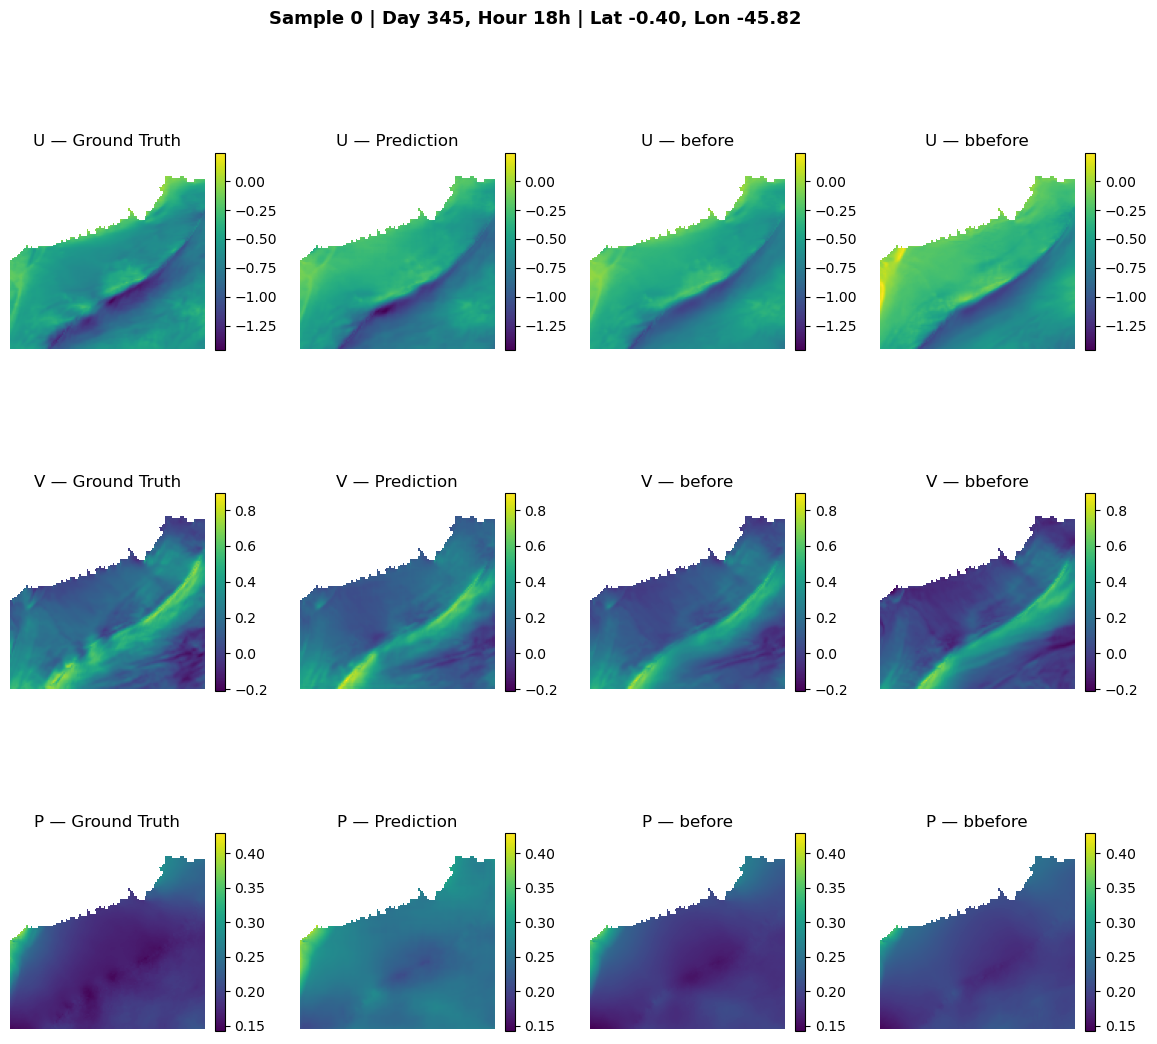

Saved to output_sample_1.png


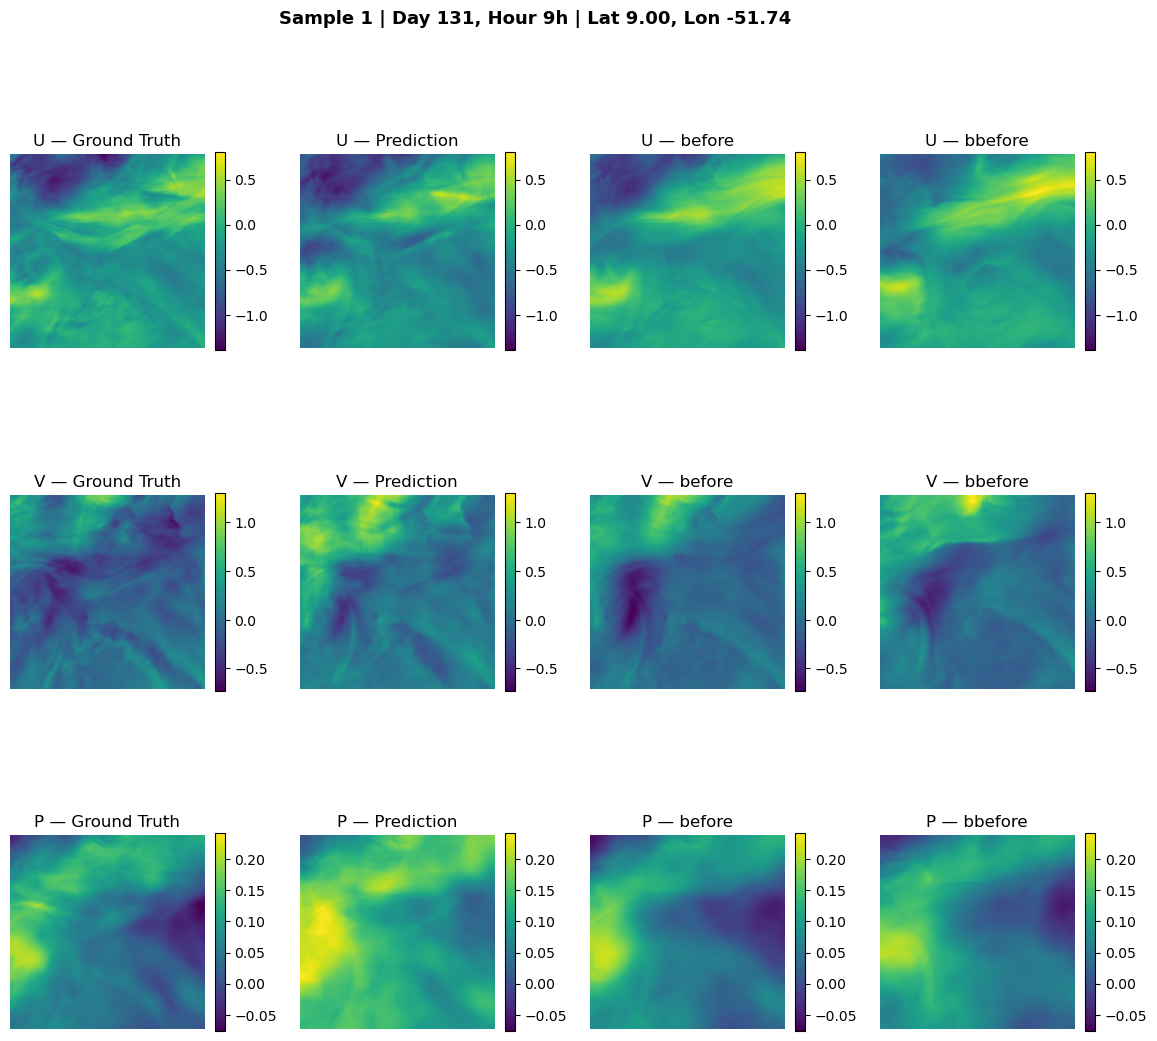

Saved to output_sample_2.png


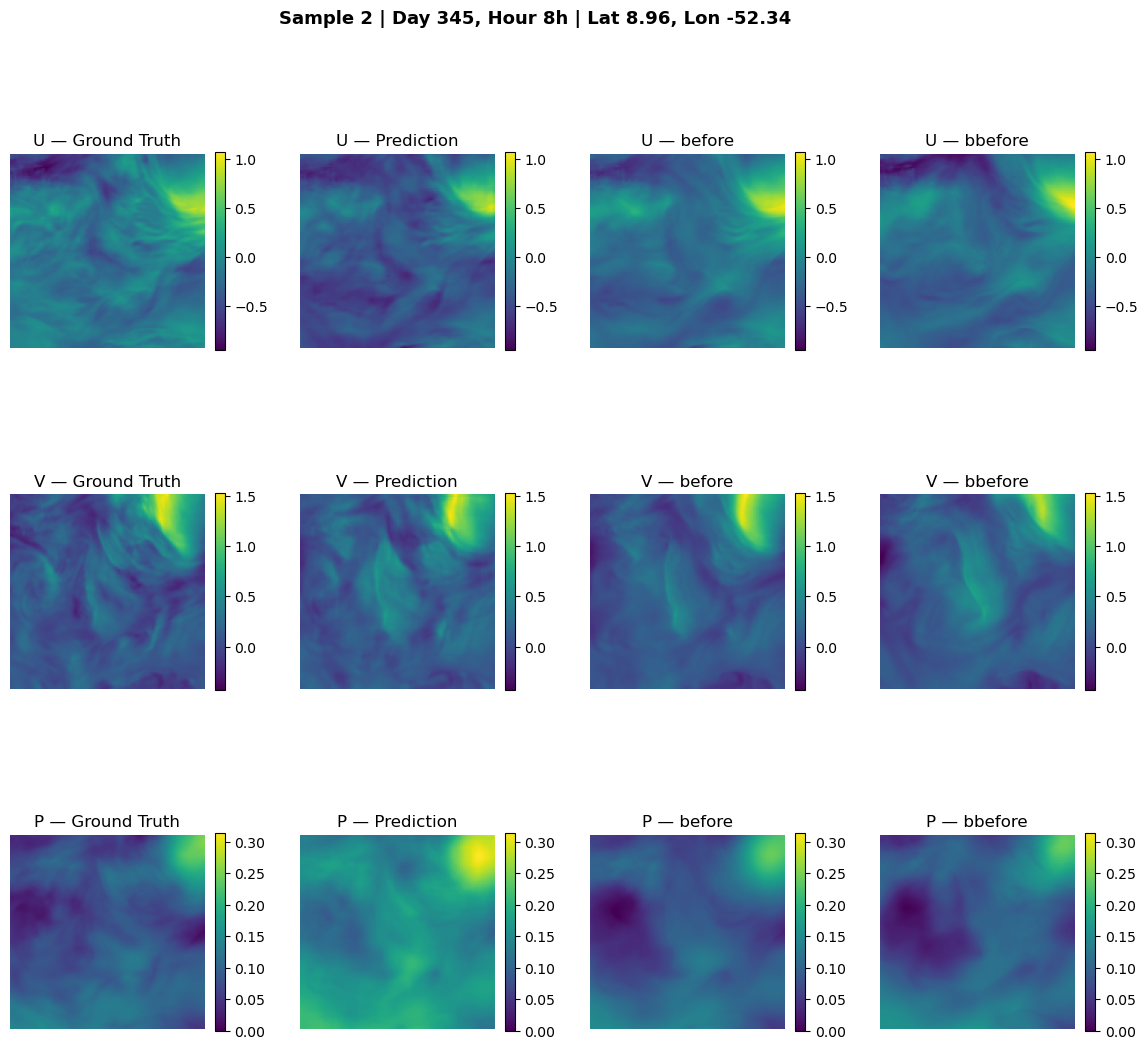

Saved to output_sample_45.png


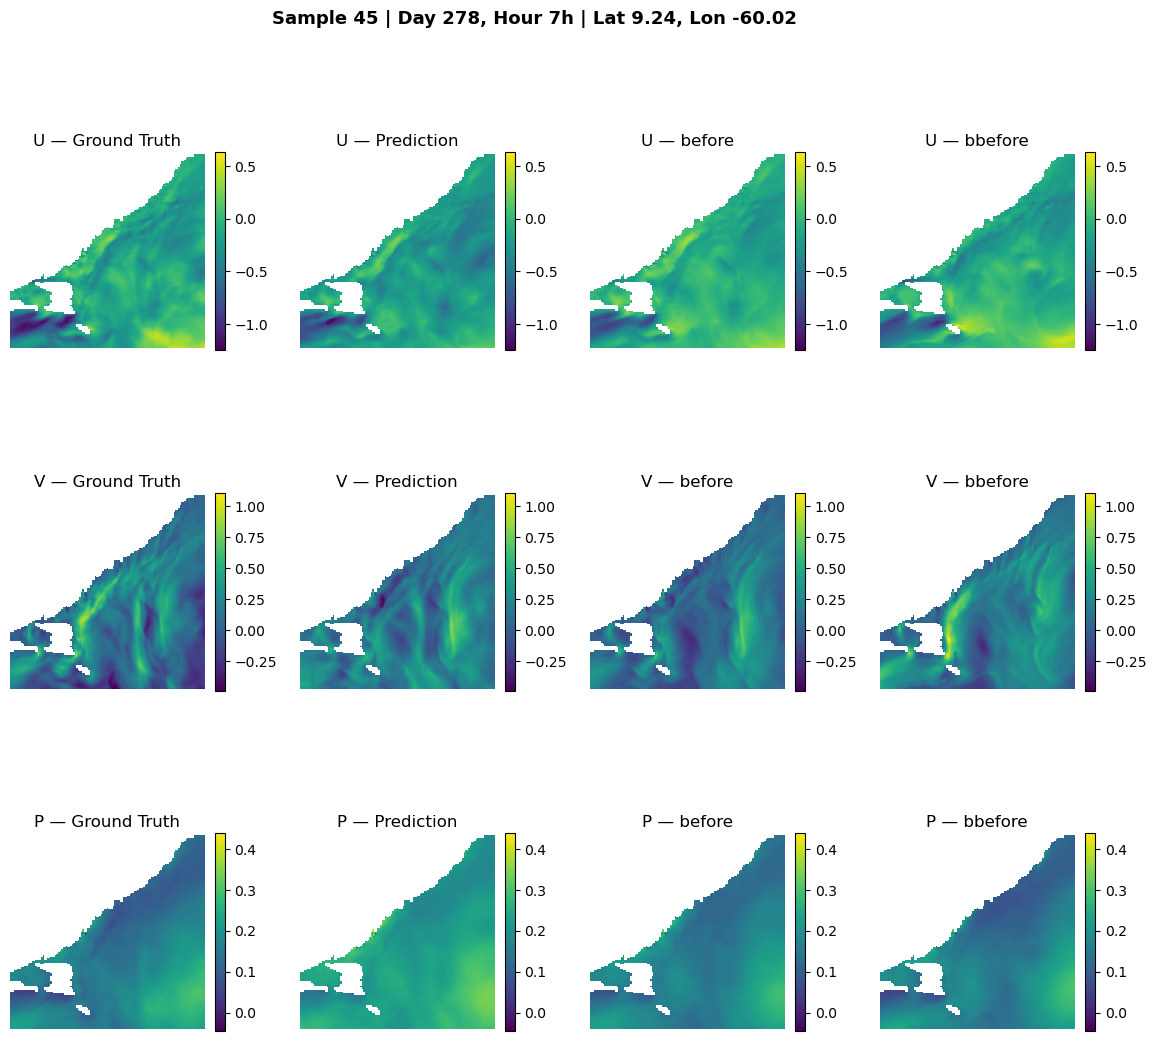

Saved to output_sample_32.png


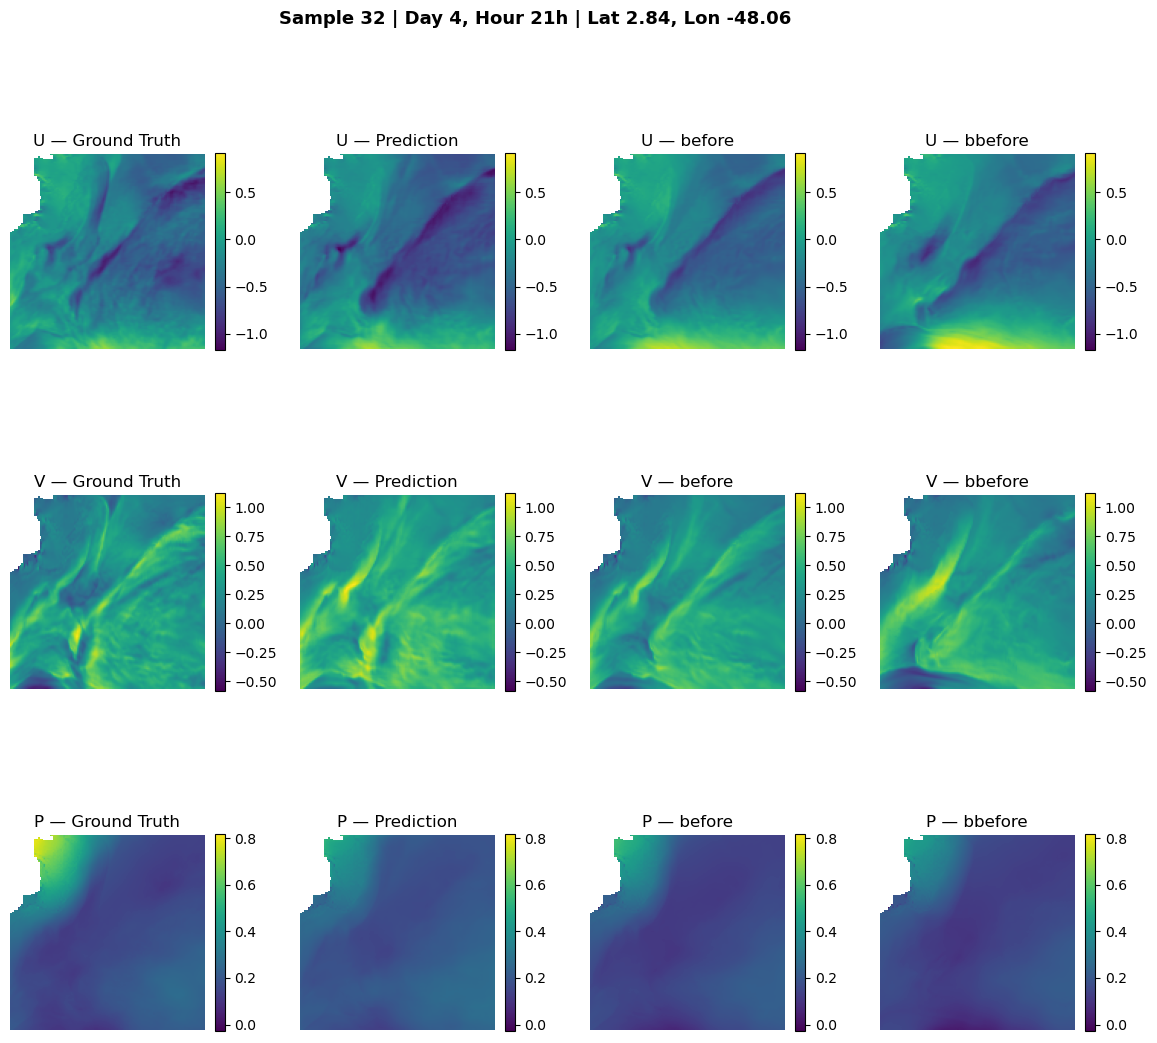

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from torch.utils.data import DataLoader
from model import DSCMS 
import segmentation_models_pytorch as smp
from singleWaveUNET import singleWaveUNet

# ----------------------------
# Load test data
# ----------------------------
def load_test_data(
    sims_path:   str = "data/sample_2020_sims.npy",
    mask_path:   str = "data/sample_2020_mask.npy",
    day_path:    str = "data/sample_2020_day.npy",
    hour_path:   str = "data/sample_2020_hour.npy",
    latlon_path: str = "data/sample_2020_latlon.npy",
    stats_path:  str = "norm_stats.pt",
    test_split:  float = 1.0,
    seed:        int = 42,
):
    sims   = torch.from_numpy(np.load(sims_path))    # [N, T, 3, H, W]
    mask   = torch.from_numpy(np.load(mask_path))    # [N, H, W]
    day    = torch.from_numpy(np.load(day_path))     # [N]
    hour   = torch.from_numpy(np.load(hour_path))    # [N]
    latlon = torch.from_numpy(np.load(latlon_path))  # [N, 2]

    N = len(sims)
    rng = np.random.default_rng(seed)
    indices = rng.permutation(N)
    n_test  = int(N * test_split)

    test_idx = indices[:n_test]

    # Load normalization stats from training
    stats = torch.load(stats_path, map_location="cpu")
    mean  = stats["mean"]   # [1, 9, 1, 1]
    std   = stats["std"]    # [1, 9, 1, 1]
    mean_x = mean.repeat(1, 3, 1, 1)  # [1, 9, 1, 1]
    std_x  = std.repeat(1, 3, 1, 1)   # [1, 9, 1, 1]

    return {
        "sims":   sims[test_idx],    # [N_test, T, 3, H, W]
        "mask":   mask[test_idx],    # [N_test, H, W]
        "day":    day[test_idx],     # [N_test]
        "hour":   hour[test_idx],    # [N_test]
        "latlon": latlon[test_idx],  # [N_test, 2]
        "mean":   mean_x,
        "std":    std_x
    }


# ----------------------------
# Inference
# ----------------------------
def run_inference(
    model:      torch.nn.Module,
    test_data:  dict,
    device:     str = "cuda" if torch.cuda.is_available() else "cpu",
    batch_size: int = 16,
):
    model = model.to(device).eval()

    sims = test_data["sims"]  # [N, T, 3, H, W]
    mean = test_data["mean"]   # [1, 9, 1, 1]
    std  = test_data["std"]    # [1, 9, 1, 1]    

    # Build inputs/targets same as training
    x1 = torch.cat([sims[:, 1], sims[:, 2], sims[:, 3]], dim=1).float()  # [N, 9, H, W]
    x1 = (x1 - mean) / (std + 1e-8)

    # Build and normalize y
    y_mean = mean[:, :3, :, :]   # [1, 3, 1, 1]
    y_std  = std[:, :3, :, :]    # [1, 3, 1, 1]
    y = (sims[:, 3] - sims[:, 2]).float()
    y = (y - y_mean) / (y_std + 1e-8)                                # [N, 3, H, W]

    dataset    = torch.utils.data.TensorDataset(x1, y)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    preds1,preds2,preds3, targets = [], [], [], []
    criterion = torch.nn.MSELoss()
    total_loss = 0.0

    with torch.no_grad():
        for x_batch, y_batch in dataloader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            pred1 = model(x_batch)
            pred1 = pred1 + x_batch[:, -3:]  # Add last 3 channels (befor) to get actual prediction
            x_batch2 = torch.cat([x_batch[:, 3:6], x_batch[:, 6:9], pred1], dim=1)
            pred2 = model(x_batch2)
            pred2 = pred2 + x_batch2[:, -3:]
            x_batch3 = torch.cat([x_batch[:, 6:9], x_batch2[:, -3:], pred2], dim=1)
            pred3 = model(x_batch3)            

            total_loss += criterion(pred3, y_batch).item() * x_batch.size(0)
            preds1.append(pred1.cpu())
            preds2.append(pred2.cpu())
            preds3.append(pred3.cpu())
            targets.append(y_batch.cpu())

    preds1   = torch.cat(preds1,   dim=0)   # [N, 3, H, W]
    preds2   = torch.cat(preds2,   dim=0)   # [N, 3, H, W]
    preds3   = torch.cat(preds3,   dim=0)   # [N, 3, H, W]
    targets = torch.cat(targets, dim=0)   # [N, 3, H, W]
    mse     = total_loss / len(dataset)

    print(f"Test MSE (normalized): {mse:.6f} | RMSE: {mse**0.5:.6f}")

    # Denormalize back to original scale for plotting
    preds_denorm1   = preds1   * (y_std + 1e-8) + y_mean   # [N, 3, H, W]
    preds_denorm2   = preds2   * (y_std + 1e-8) + y_mean   # [N, 3, H, W]
    preds_denorm3   = preds3   * (y_std + 1e-8) + y_mean   # [N, 3, H, W]

    # targets_denorm = targets * (y_std + 1e-8) + y_mean   # [N, 3, H, W]

    # mse_denorm = torch.mean((preds_denorm - targets_denorm) ** 2).item()
    # print(f"Test MSE (original scale): {mse_denorm:.6f} | RMSE: {mse_denorm**0.5:.6f}")

    return sims[:, 1],sims[:, 2],sims[:, 3],sims[:, 4],sims[:, 5],sims[:, 6],preds_denorm1,preds_denorm2,preds_denorm3


def apply_mask(field: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """Set masked regions (mask==1) to NaN so imshow skips them."""
    out = field.copy()
    out[mask == 1] = np.nan
    return out

# ----------------------------
# Plot
# ----------------------------
CHANNEL_NAMES = ["U", "V", "P"]  # adjust to your fields

def plot_sample(
    s1:   torch.Tensor,
    s2:    torch.Tensor,
    s3:    torch.Tensor,   # [N, 3, H, W]
    s4:    torch.Tensor,   # [N, 3, H, W]
    s5:    torch.Tensor,   # [N, 3, H, W]
    s6:    torch.Tensor,   # [N, 3, H, W]
    p1:    torch.Tensor,   # [N, 3, H, W]
    p2:    torch.Tensor,   # [N, 3, H, W
    p3:    torch.Tensor,   # [N, 3, H, W]
    test_data: dict,
    sample_idx: int = 0,
    save_path:  str = None,
):
    s1 = s1[sample_idx].numpy()  # [3, H, W]
    s2 = s2[sample_idx].numpy()   # [3, H, W]
    s3 = s3[sample_idx].numpy()   # [3, H, W]
    s4 = s4[sample_idx].numpy()   # [3, H, W]
    s5 = s5[sample_idx].numpy()   # [3, H, W]
    s6 = s6[sample_idx].numpy()   # [3, H, W]
    p1 = p1[sample_idx].numpy()   # [3, H, W]
    p2 = p2[sample_idx].numpy()   # [3, H, W]
    p3 = p3[sample_idx].numpy()   # [3, H, W]
    mask   = test_data["mask"][sample_idx].numpy()  # [H, W]
    day    = test_data["day"][sample_idx].item()
    hour   = test_data["hour"][sample_idx].item()
    lat, lon = test_data["latlon"][sample_idx].tolist()

    n_channels = p1.shape[0]  # 3
    fig = plt.figure(figsize=(14, 4 * n_channels))
    fig.suptitle(
        f"Sample {sample_idx} | Day {day}, Hour {hour}h | "
        f"Lat {lat:.2f}, Lon {lon:.2f}",
        fontsize=13, fontweight="bold"
    )

    gs = gridspec.GridSpec(n_channels, 6, figure=fig, wspace=0.35, hspace=0.4)

    for ch in range(n_channels):
        ss1 = apply_mask(s1[ch],  mask)
        ss2 = apply_mask(s2[ch],  mask)
        ss3 = apply_mask(s3[ch],  mask)
        ss4 = apply_mask(s4[ch],  mask)
        ss5 = apply_mask(s5[ch],  mask)
        ss6 = apply_mask(s6[ch],  mask)
        pp1 = apply_mask(p1[ch],  mask)
        pp2 = apply_mask(p2[ch],  mask)
        pp3 = apply_mask(p3[ch],  mask)

        vmin = np.nanmin([ss1, ss2, ss3, ss4, ss5, ss6, pp1, pp2, pp3])
        vmax = np.nanmax([ss1, ss2, ss3, ss4, ss5, ss6, pp1, pp2, pp3])

        # vmin = min(target[ch].min(), pred[ch].min(),befor.min(),bbfore.min())
        # vmax = max(target[ch].max(), pred[ch].max(),befor.max(),bbfore.max())
        # diff = pred[ch] - target[ch]
        # clim = max(abs(diff.min()), abs(diff.max()))

        # yesterday before
        ax0 = fig.add_subplot(gs[ch, 0])
        im0 = ax0.imshow(ss1, vmin=vmin, vmax=vmax, cmap="viridis")
        ax0.set_title(f"{CHANNEL_NAMES[ch]} — t[n-2]")
        ax0.axis("off")
        plt.colorbar(im0, ax=ax0, fraction=0.046)

        # yesterday
        ax1 = fig.add_subplot(gs[ch, 1])
        im1 = ax1.imshow(ss2, vmin=vmin, vmax=vmax, cmap="viridis")
        ax1.set_title(f"{CHANNEL_NAMES[ch]} — t[n-1]")
        ax1.axis("off")
        plt.colorbar(im1, ax=ax1, fraction=0.046)

        # today
        ax2 = fig.add_subplot(gs[ch, 2])
        im2 = ax2.imshow(ss3, vmin=vmin, vmax=vmax, cmap="viridis")
        ax2.set_title(f"{CHANNEL_NAMES[ch]} — t[n]")
        ax2.axis("off")
        plt.colorbar(im2, ax=ax2, fraction=0.046)

        # 4 days
        ax3 = fig.add_subplot(gs[ch, 3])
        im3 = ax3.imshow(ss4, vmin=vmin, vmax=vmax, cmap="viridis")
        ax3.set_title(f"{CHANNEL_NAMES[ch]} — t[n+1]")
        ax3.axis("off")
        plt.colorbar(im3, ax=ax3, fraction=0.046)

        # 8 days
        ax3 = fig.add_subplot(gs[ch, 3])
        im3 = ax3.imshow(ss5, vmin=vmin, vmax=vmax, cmap="viridis")
        ax3.set_title(f"{CHANNEL_NAMES[ch]} — t[n+2]")
        ax3.axis("off")
        plt.colorbar(im3, ax=ax3, fraction=0.046)

        # 12 days
        ax3 = fig.add_subplot(gs[ch, 3])
        im3 = ax3.imshow(ss6, vmin=vmin, vmax=vmax, cmap="viridis")
        ax3.set_title(f"{CHANNEL_NAMES[ch]} — t[n+3]")
        ax3.axis("off")
        plt.colorbar(im3, ax=ax3, fraction=0.046)


    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved to {save_path}")
    plt.show()


# ----------------------------
# Usage
# ----------------------------
# model = DSCMS(in_channels=9, out_channels=3)
# model = smp.Unet(
#     encoder_name="resnet18",
#     in_channels=9,
#     classes=3,
# )

model = singleWaveUNet(
    in_channels=9,
    out_channels=3,
    depth=3,                 # variable depth
    base_channels=32,
    bottleneck_reduction=2,  # reduced bottleneck
)

model.load_state_dict(torch.load("best_modelW.pth", map_location="cpu"))

test_data = load_test_data()
#bbefor,befor,preds, targets, mse = run_inference(model, test_data)
s1,s2,s3,s4,s5,s6,p1,p2,p3 = run_inference(model, test_data)

# Plot a few samples
for i in [0, 1, 2,45,32]:
    #plot_sample(bbefor,befor,preds, targets, test_data, sample_idx=i, save_path=f"output_sample_{i}.png")
    plot_sample(s1,s2,s3,s4,s5,s6,p1,p2,p3, test_data, sample_idx=i, save_path=f"output_sample_{i}.png")